# Trabajo Práctico: Análisis exploratorio del historial de Spotify

En este notebook se analiza el historial extendido de reproducciones de un usuario de Spotify
(`StreamingHistory_Extended.csv`). El objetivo es entender **qué**, **cuánto** y **cuándo** escucha
este usuario, usando Pandas para procesar los datos y Matplotlib/Seaborn para visualizarlos.

**Estructura del notebook**

1. Carga y descripción del dataset
2. Limpieza de datos y nuevas columnas
3. Preguntas de la consigna (puntos 2 a 9)
4. Análisis adicionales (punto 10)
5. Bonus: días, horarios, meses y canciones salteadas
6. Bonus 2: información extra con la API de Spotify (`spotipy`)
7. Conclusiones

In [ ]:
# Librerías principales
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Configuración de visualización de DataFrames
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

# Paleta y estilo común para todos los gráficos
COLOR_PRINCIPAL: str = "#2a78d6"   # azul: serie principal
COLOR_SECUNDARIO: str = "#eb6834"  # naranja: serie de comparación
COLOR_TEXTO: str = "#52514e"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLOR_TEXTO,
    "ytick.color": COLOR_TEXTO,
})

# Ruta del archivo y zona horaria del usuario (las conexiones son casi todas desde Argentina)
RUTA_DATASET: str = "StreamingHistory_Extended.csv"
ZONA_HORARIA_LOCAL: str = "America/Argentina/Buenos_Aires"
MS_POR_HORA: int = 1000 * 60 * 60

## 1. ¿Qué información contiene el dataset?

Se carga el CSV completo. Se usa `low_memory=False` porque la columna `skipped` tiene tipos
mezclados y, si no, Pandas emite una advertencia al inferir el tipo por partes.

In [2]:
# Carga del archivo original, sin modificaciones
df_crudo: pd.DataFrame = pd.read_csv(RUTA_DATASET, low_memory=False)

cantidad_filas, cantidad_columnas = df_crudo.shape
print(f"El dataset tiene {cantidad_filas:,} registros y {cantidad_columnas} columnas.\n")
df_crudo.info()

El dataset tiene 125,349 registros y 20 columnas.

<class 'pandas.DataFrame'>
RangeIndex: 125349 entries, 0 to 125348
Data columns (total 20 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   ts                                 125349 non-null  str  
 1   username                           125349 non-null  int64
 2   platform                           125349 non-null  str  
 3   ms_played                          125349 non-null  int64
 4   conn_country                       125349 non-null  str  
 5   user_agent_decrypted               104897 non-null  str  
 6   master_metadata_track_name         123953 non-null  str  
 7   master_metadata_album_artist_name  123953 non-null  str  
 8   master_metadata_album_album_name   123953 non-null  str  
 9   spotify_track_uri                  123953 non-null  str  
 10  episode_name                       168 non-null     str  
 11  episode_show_name        

In [3]:
# Primeros registros para ver el formato de cada columna
df_crudo.head()

,ts,username,platform,ms_played,conn_country,user_agent_decrypted,master_metadata_track_name,master_metadata_album_artist_name,master_metadata_album_album_name,spotify_track_uri,episode_name,episode_show_name,spotify_episode_uri,reason_start,reason_end,shuffle,skipped,offline,offline_timestamp,is_podcast
0,2020-12-06T02:51:11Z,11145402699,"iOS 14.2 (iPhone12,3)",145610,AR,unknown,Hey Jude - Remastered 2015,The Beatles,1,spotify:track:0aym2LBJBk9DAYuHHutrIl,NaN,NaN,NaN,trackdone,fwdbtn,True,NaN,False,1607222710755,False
1,2020-12-06T02:53:31Z,11145402699,"iOS 14.2 (iPhone12,3)",138692,AR,unknown,Hacer un puente,La Franela,Hacer Un Puente,spotify:track:18Q3WTfyWX1tdS1cp42NhA,NaN,NaN,NaN,fwdbtn,fwdbtn,True,NaN,False,1607223071185,False
2,2020-12-06T02:53:53Z,11145402699,"iOS 14.2 (iPhone12,3)",22662,AR,unknown,Happy Together - Remastered,The Turtles,All the Singles,spotify:track:2admbUc576sC6M0QeUkg2C,NaN,NaN,NaN,fwdbtn,fwdbtn,True,NaN,False,1607223210387,False
3,2020-12-06T02:53:56Z,11145402699,"iOS 14.2 (iPhone12,3)",2716,AR,unknown,Demons,Imagine Dragons,Night Visions,spotify:track:5qaEfEh1AtSdrdrByCP7qR,NaN,NaN,NaN,fwdbtn,fwdbtn,True,NaN,False,1607223233165,False
4,2020-12-06T02:53:57Z,11145402699,"iOS 14.2 (iPhone12,3)",116,AR,unknown,"Paint It, Black",The Rolling Stones,Aftermath,spotify:track:63T7DJ1AFDD6Bn8VzG6JE8,NaN,NaN,NaN,fwdbtn,fwdbtn,True,NaN,False,1607223236453,False


### Descripción de las columnas

| Columna | Tipo leído | Descripción |
|---|---|---|
| `ts` | texto | Fecha y hora (UTC) en la que **terminó** la reproducción. Hay que convertirla a `datetime`. |
| `username` | entero | Identificador del usuario. |
| `platform` | texto | Dispositivo / sistema operativo desde el que se reprodujo. |
| `ms_played` | entero | **Milisegundos reproducidos.** Es la columna clave para medir cuánto se escuchó. |
| `conn_country` | texto | País desde el que se conectó. |
| `user_agent_decrypted` | texto | Navegador/cliente usado (casi siempre `unknown`). |
| `master_metadata_track_name` | texto | Nombre de la canción. |
| `master_metadata_album_artist_name` | texto | Artista. |
| `master_metadata_album_album_name` | texto | Álbum. |
| `spotify_track_uri` | texto | Identificador único de la canción en Spotify. |
| `episode_name`, `episode_show_name`, `spotify_episode_uri` | texto | Datos del episodio, solo para podcasts. |
| `reason_start` / `reason_end` | texto | Por qué empezó / terminó la reproducción (`trackdone`, `fwdbtn` = botón siguiente, `clickrow`, etc.). |
| `shuffle` | booleano | Si estaba activado el modo aleatorio. |
| `skipped` | mixto | Si la canción fue salteada. Tiene valores mezclados (`True`, `False`, `1.0`, `0.0`). |
| `offline` | booleano | Si se reprodujo sin conexión. |
| `offline_timestamp` | entero | Marca de tiempo (Unix, ms) asociada al modo offline. |
| `is_podcast` | booleano | Si el registro es un episodio de podcast. |

A continuación se revisan los valores nulos y algunas columnas puntuales para decidir cuáles sirven.

In [4]:
# Cantidad y porcentaje de valores nulos por columna
nulos_por_columna: pd.DataFrame = pd.DataFrame({
    "nulos": df_crudo.isna().sum(),
    "porcentaje": (df_crudo.isna().mean() * 100).round(2),
}).sort_values("nulos", ascending=False)
nulos_por_columna

,nulos,porcentaje
episode_show_name,125181,99.87
spotify_episode_uri,125181,99.87
episode_name,125181,99.87
skipped,108995,86.95
user_agent_decrypted,20452,16.32
reason_end,19610,15.64
spotify_track_uri,1396,1.11
master_metadata_track_name,1396,1.11
master_metadata_album_artist_name,1396,1.11
master_metadata_album_album_name,1396,1.11


In [5]:
# Columnas con poca o ninguna información útil para el análisis
usuarios_distintos: int = df_crudo["username"].nunique()
print(f"Usuarios distintos: {usuarios_distintos}")

porcentaje_user_agent_unknown: float = (df_crudo["user_agent_decrypted"] == "unknown").mean() * 100
print(f"user_agent_decrypted = 'unknown' en el {porcentaje_user_agent_unknown:.1f}% de los registros")

print("\nPaíses de conexión:")
print(df_crudo["conn_country"].value_counts())

print("\nValores de la columna 'skipped' (tipos mezclados):")
print(df_crudo["skipped"].map(lambda valor: f"{valor!r} ({type(valor).__name__})").value_counts())

Usuarios distintos: 1
user_agent_decrypted = 'unknown' en el 83.0% de los registros

Países de conexión:
conn_country
AR    122666
BR      1852
ZZ       341
CL       279
CR       117
US        47
UY        47
Name: count, dtype: int64

Valores de la columna 'skipped' (tipos mezclados):
skipped
nan (float)      108995
'False' (str)      4873
'True' (str)       4179
'1.0' (str)        4017
'0.0' (str)        3285
Name: count, dtype: int64


**Observaciones sobre las columnas**

- `username` tiene un único valor (es un solo usuario), así que no aporta información.
- `user_agent_decrypted` es `unknown` en la gran mayoría de los casos y además tiene nulos.
- `offline_timestamp` es un dato técnico que no se necesita (ya tenemos `ts`).
- `episode_name`, `episode_show_name` y `spotify_episode_uri` solo tienen datos en los podcasts.
- `skipped` tiene valores de distintos tipos que representan lo mismo (`True` y `1.0`, `False` y `0.0`);
  hay que normalizarla.
- `conn_country`: casi todo es Argentina (`AR`), con algunas conexiones desde Brasil, Chile, etc.
  (probablemente viajes).

### ¿Son todos los registros del mismo tipo?

No. Hay tres tipos de registros:

In [6]:
def clasificar_registro(fila: pd.Series) -> str:
    """Devuelve el tipo de registro: podcast, canción o sin metadata."""
    if fila["is_podcast"]:
        return "Podcast"
    if pd.isna(fila["master_metadata_track_name"]):
        return "Sin metadata"
    return "Canción"


df_crudo["tipo_registro"] = df_crudo.apply(clasificar_registro, axis=1)

registros_por_tipo: pd.DataFrame = (
    df_crudo.groupby("tipo_registro")
    .agg(registros=("ms_played", "size"), horas=("ms_played", lambda ms: ms.sum() / MS_POR_HORA))
    .round(1)
    .sort_values("registros", ascending=False)
)
registros_por_tipo

,registros,horas
tipo_registro,,
Canción,123953,3433.6
Sin metadata,1228,33.0
Podcast,168,28.9


- **Canciones**: la enorme mayoría.
- **Podcasts**: 168 episodios. No tienen nombre de canción ni artista, así que no entran en las preguntas
  sobre canciones.
- **Sin metadata**: 1.228 registros que no son podcasts pero tampoco tienen canción, artista ni URI.
  No se puede saber qué sonó (posiblemente contenido que ya no está disponible), así que se descartan.

Además, hay reproducciones con `ms_played = 0` (se registraron pero no sonaron). Se conservan porque no
suman tiempo, pero se tienen en cuenta al contar canciones distintas.

## 2. Limpieza de datos y nuevas columnas

Pasos de limpieza:

1. Quedarse solo con los registros de **canciones**.
2. Eliminar las columnas que no se usan.
3. Renombrar las columnas a nombres cortos en español.
4. Convertir `ts` a `datetime` y pasarlo a **hora de Argentina** (viene en UTC; sin esto, el análisis por
   horario estaría corrido 3 horas).
5. Normalizar `skipped` a booleano.
6. Crear columnas derivadas: horas reproducidas, año, mes, día de la semana, hora del día, y un
   identificador de canción (canción + artista).

In [7]:
# Columnas que no aportan al análisis de canciones
COLUMNAS_DESCARTADAS: list[str] = [
    "username", "user_agent_decrypted", "offline_timestamp",
    "episode_name", "episode_show_name", "spotify_episode_uri",
    "is_podcast", "tipo_registro",
]

# Nombres más cortos y descriptivos
NOMBRES_COLUMNAS: dict[str, str] = {
    "ts": "fecha_utc",
    "platform": "plataforma",
    "conn_country": "pais",
    "master_metadata_track_name": "cancion",
    "master_metadata_album_artist_name": "artista",
    "master_metadata_album_album_name": "album",
    "spotify_track_uri": "uri",
    "reason_start": "motivo_inicio",
    "reason_end": "motivo_fin",
    "skipped": "salteada",
}

# Nos quedamos solo con canciones; .copy() evita modificar df_crudo por referencia
df_canciones: pd.DataFrame = (
    df_crudo[df_crudo["tipo_registro"] == "Canción"]
    .drop(columns=COLUMNAS_DESCARTADAS)
    .rename(columns=NOMBRES_COLUMNAS)
    .copy()
)

print(f"Registros de canciones: {len(df_canciones):,} "
      f"(se descartaron {len(df_crudo) - len(df_canciones):,})")

Registros de canciones: 123,953 (se descartaron 1,396)


In [8]:
def normalizar_salteo(valor: object) -> bool | None:
    """Convierte los distintos formatos de 'skipped' (True, 'True', 1.0, '1.0'...) a booleano."""
    if pd.isna(valor):
        return None
    return str(valor).strip().lower() in ("true", "1", "1.0")


df_canciones["salteada"] = df_canciones["salteada"].map(normalizar_salteo).astype("boolean")

# Fechas: texto -> datetime en UTC -> hora local de Argentina
df_canciones["fecha_utc"] = pd.to_datetime(df_canciones["fecha_utc"], utc=True)
df_canciones["fecha"] = df_canciones["fecha_utc"].dt.tz_convert(ZONA_HORARIA_LOCAL)

# Nombres en español para días y meses (no dependemos del idioma del sistema)
DIAS_SEMANA: list[str] = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MESES: list[str] = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# Columnas derivadas de la fecha
df_canciones["anio"] = df_canciones["fecha"].dt.year
df_canciones["mes"] = df_canciones["fecha"].dt.month
df_canciones["anio_mes"] = df_canciones["fecha"].dt.strftime("%Y-%m")
df_canciones["dia_semana"] = df_canciones["fecha"].dt.dayofweek  # 0 = lunes
df_canciones["nombre_dia"] = df_canciones["dia_semana"].map(lambda dia: DIAS_SEMANA[dia])
df_canciones["hora"] = df_canciones["fecha"].dt.hour

# Duración en horas (más fácil de leer que milisegundos)
df_canciones["horas"] = df_canciones["ms_played"] / MS_POR_HORA

# Identificador de canción: nombre + artista (ver punto 3)
df_canciones["cancion_artista"] = df_canciones["cancion"] + " — " + df_canciones["artista"]

df_canciones = df_canciones.sort_values("fecha").reset_index(drop=True)
df_canciones.head()

,fecha_utc,plataforma,ms_played,pais,cancion,artista,album,uri,motivo_inicio,motivo_fin,shuffle,salteada,offline,fecha,anio,mes,anio_mes,dia_semana,nombre_dia,hora,horas,cancion_artista
0,2014-06-27 18:01:15+00:00,"iOS 7.0.4 (iPod5,1)",0,AR,Mejor,Los Tipitos,Push,spotify:track:5LFl6vXC2CwcciAbymL4jZ,clickrow,fwdbtn,False,True,False,2014-06-27 15:01:15-03:00,2014,6,2014-06,4,Viernes,15,0.000000,Mejor — Los Tipitos
1,2014-06-27 18:01:16+00:00,"iOS 7.0.4 (iPod5,1)",0,AR,Algo Demencial,Los Tipitos,Push,spotify:track:0rqD0zvqI4GrvyUxyQ7Ij3,fwdbtn,fwdbtn,True,True,False,2014-06-27 15:01:16-03:00,2014,6,2014-06,4,Viernes,15,0.000000,Algo Demencial — Los Tipitos
2,2014-06-29 20:10:10+00:00,"iOS 7.0.4 (iPod5,1)",33062,AR,Iron Man - Live,Black Sabbath,Past Lives,spotify:track:1XtZ3GROvmy4JrT6uMvsD8,NaN,fwdbtn,False,True,False,2014-06-29 17:10:10-03:00,2014,6,2014-06,6,Domingo,17,0.009184,Iron Man - Live — Black Sabbath
3,2014-06-29 20:10:54+00:00,"iOS 7.0.4 (iPod5,1)",44505,AR,Sultans Of Swing,Dire Straits,Dire Straits,spotify:track:3LTMnFa0hhwisyq6ILahyj,fwdbtn,fwdbtn,False,True,False,2014-06-29 17:10:54-03:00,2014,6,2014-06,6,Domingo,17,0.012363,Sultans Of Swing — Dire Straits
4,2014-06-29 20:11:16+00:00,"iOS 7.0.4 (iPod5,1)",22941,AR,Fortunate Son,Creedence Clearwater Revival,Willy And The Poor Boys,spotify:track:7I2lPuuiOkpKtZlhr4zUpT,fwdbtn,fwdbtn,False,True,False,2014-06-29 17:11:16-03:00,2014,6,2014-06,6,Domingo,17,0.006372,Fortunate Son — Creedence Clearwater Revival


In [9]:
# Verificación: ya no hay nulos en las columnas que vamos a usar
COLUMNAS_CLAVE: list[str] = ["fecha", "cancion", "artista", "album", "uri", "ms_played"]
df_canciones[COLUMNAS_CLAVE].isna().sum()

fecha        0
cancion      0
artista      0
album        0
uri          0
ms_played    0
dtype: int64

Las columnas clave ya no tienen nulos. Quedan nulos en `salteada` (solo se registró en los últimos años,
se ve en el bonus) y en `motivo_fin`, pero no afectan a las preguntas principales.

## 3. Preguntas de la consigna

### Punto 2: ¿Desde qué fecha y hasta qué fecha hay reproducciones?

In [10]:
fecha_primera: pd.Timestamp = df_canciones["fecha"].min()
fecha_ultima: pd.Timestamp = df_canciones["fecha"].max()
dias_cubiertos: int = (fecha_ultima - fecha_primera).days

print(f"Primera reproducción: {fecha_primera:%d/%m/%Y %H:%M}")
print(f"Última reproducción:  {fecha_ultima:%d/%m/%Y %H:%M}")
print(f"Período cubierto: {dias_cubiertos:,} días (~{dias_cubiertos / 365:.1f} años)\n")

# Cantidad de reproducciones por año, para ver si el registro es parejo
reproducciones_por_anio: pd.Series = df_canciones.groupby("anio").size()
print("Reproducciones por año:")
print(reproducciones_por_anio.to_string())

Primera reproducción: 27/06/2014 15:01
Última reproducción:  23/05/2024 20:56
Período cubierto: 3,618 días (~9.9 años)

Reproducciones por año:
anio
2014       10
2016        1
2017    16578
2018    20054
2019    21821
2020    25659
2021    15005
2022    10366
2023    10997
2024     3462


El historial va de **junio de 2014 a mayo de 2024**. Sin embargo, 2014 y 2016 tienen apenas un puñado de
reproducciones y no hay ninguna en 2015: el uso real y continuo empieza en **2017**.
2024 está incompleto (termina en mayo). Esto es importante para no sacar conclusiones equivocadas al
comparar años o meses.

### Punto 3: ¿Cuántas canciones diferentes se escucharon?

**El problema:** el nombre de la canción no la identifica de forma única, porque hay canciones distintas
con el mismo nombre. Por ejemplo:

In [11]:
# Cantidad de artistas distintos que tienen una canción con cada nombre
artistas_por_nombre: pd.Series = (
    df_canciones.groupby("cancion")["artista"].nunique().sort_values(ascending=False)
)
print("Nombres de canción compartidos por más artistas:")
print(artistas_por_nombre.head(5).to_string())

print("\nArtistas con una canción llamada 'Friends':")
print(sorted(df_canciones.loc[df_canciones["cancion"] == "Friends", "artista"].unique()))

Nombres de canción compartidos por más artistas:
cancion
Friends    7
Believe    6
Replay     5
Jovial     5
Rain       4

Artistas con una canción llamada 'Friends':
['Chase Atlantic', 'Cheryl Allie', 'Dido', 'Ed Sheeran', 'Ella Henderson', 'Solomun', 'levitation room']


Hay tres formas de contar:

- **Por nombre**: subestima, porque junta canciones distintas con el mismo nombre.
- **Por URI de Spotify**: sobreestima, porque una misma canción puede tener varios URI (por ejemplo,
  si aparece en el álbum original y en un compilado).
- **Por nombre + artista**: es la opción más razonable. Separa canciones homónimas de distintos artistas
  y une las versiones repetidas de una misma canción.

Se usa **nombre + artista** (columna `cancion_artista`) y se cuentan solo las que sonaron más de 0 ms.

In [12]:
# Ejemplo de una misma canción con varios URI
uris_por_cancion: pd.Series = (
    df_canciones.groupby("cancion_artista")["uri"].nunique().sort_values(ascending=False)
)
print("Canciones con más URI distintos (misma canción en distintos álbumes):")
print(uris_por_cancion.head(3).to_string(), "\n")

# Solo reproducciones que efectivamente sonaron
df_reproducidas: pd.DataFrame = df_canciones[df_canciones["ms_played"] > 0]

conteo_canciones: pd.Series = pd.Series({
    "Por nombre": df_reproducidas["cancion"].nunique(),
    "Por URI": df_reproducidas["uri"].nunique(),
    "Por nombre + artista": df_reproducidas["cancion_artista"].nunique(),
})
print("Canciones distintas según el criterio:")
print(conteo_canciones.to_string())

canciones_distintas: int = conteo_canciones["Por nombre + artista"]
artistas_distintos: int = df_reproducidas["artista"].nunique()
print(f"\nRespuesta: se escucharon {canciones_distintas:,} canciones distintas "
      f"de {artistas_distintos:,} artistas.")

Canciones con más URI distintos (misma canción en distintos álbumes):
cancion_artista
Seven Days — Sting                                        8
Seven Nation Army (feat. KOYSINA) — Dance Fruits Music    8
Mil Horas — Los Abuelos De La Nada                        6 

Canciones distintas según el criterio:
Por nombre               9036
Por URI                 10781
Por nombre + artista     9568

Respuesta: se escucharon 9,568 canciones distintas de 3,335 artistas.


### Punto 4: ¿Cuál es la duración total de las reproducciones?

La columna `ms_played` indica cuántos milisegundos sonó cada reproducción. Se suman todas.

In [13]:
def formatear_duracion(milisegundos: float) -> str:
    """Convierte milisegundos a un texto con días, horas y minutos."""
    minutos_totales: int = int(milisegundos // 60_000)
    dias, resto_minutos = divmod(minutos_totales, 60 * 24)
    horas, minutos = divmod(resto_minutos, 60)
    return f"{dias} días, {horas} horas y {minutos} minutos"


ms_totales: int = int(df_canciones["ms_played"].sum())
horas_totales: float = ms_totales / MS_POR_HORA

print(f"Duración total: {ms_totales:,} ms")
print(f"            = {horas_totales:,.1f} horas")
print(f"            = {formatear_duracion(ms_totales)}")

# Promedio diario desde 2017 (antes casi no hay datos)
df_desde_2017: pd.DataFrame = df_canciones[df_canciones["anio"] >= 2017]
dias_desde_2017: int = (fecha_ultima - df_desde_2017["fecha"].min()).days + 1
minutos_por_dia: float = df_desde_2017["horas"].sum() * 60 / dias_desde_2017
print(f"\nPromedio desde 2017: {minutos_por_dia:.0f} minutos de música por día")

Duración total: 12,361,101,218 ms
            = 3,433.6 horas
            = 143 días, 1 horas y 38 minutos

Promedio desde 2017: 77 minutos de música por día


### Punto 5: ¿Cuál es el artista más escuchado por tiempo total?

Se agrupa por artista y se suma el tiempo reproducido.

In [14]:
# Horas totales por artista, de mayor a menor
horas_por_artista: pd.Series = (
    df_canciones.groupby("artista")["horas"].sum().sort_values(ascending=False)
)

artista_top: str = horas_por_artista.index[0]
horas_artista_top: float = horas_por_artista.iloc[0]
porcentaje_artista_top: float = horas_artista_top / horas_totales * 100

print(f"Artista más escuchado: {artista_top}")
print(f"Tiempo: {horas_artista_top:,.1f} horas ({porcentaje_artista_top:.1f}% del total)")

Artista más escuchado: Charly García
Tiempo: 82.0 horas (2.4% del total)


### Punto 6: ¿Cuál es la canción más escuchada por tiempo total?

Se agrupa por **canción + artista** (por lo explicado en el punto 3) y se suma el tiempo.

In [15]:
# Tiempo total y cantidad de reproducciones por canción
resumen_por_cancion: pd.DataFrame = (
    df_canciones.groupby(["cancion", "artista"])
    .agg(horas=("horas", "sum"), reproducciones=("ms_played", "size"))
    .sort_values("horas", ascending=False)
)

(cancion_top, artista_de_cancion_top) = resumen_por_cancion.index[0]
datos_cancion_top: pd.Series = resumen_por_cancion.iloc[0]

print(f"Canción más escuchada: '{cancion_top}' de {artista_de_cancion_top}")
print(f"Tiempo: {datos_cancion_top['horas']:.1f} horas en "
      f"{int(datos_cancion_top['reproducciones'])} reproducciones")

Canción más escuchada: 'Redbone' de Childish Gambino
Tiempo: 17.9 horas en 289 reproducciones


### Punto 7: Del artista más escuchado, ¿cuál es la canción más escuchada?

In [16]:
# Filtramos las reproducciones del artista top y agrupamos por canción
canciones_artista_top: pd.DataFrame = (
    df_canciones[df_canciones["artista"] == artista_top]
    .groupby("cancion")
    .agg(horas=("horas", "sum"), reproducciones=("ms_played", "size"))
    .sort_values("horas", ascending=False)
)

print(f"Canción más escuchada de {artista_top}: '{canciones_artista_top.index[0]}' "
      f"({canciones_artista_top['horas'].iloc[0]:.1f} horas)\n")
print(f"Top 5 canciones de {artista_top}:")
canciones_artista_top.head(5).round(1)

Canción más escuchada de Charly García: 'Hablando a Tu Corazón' (8.7 horas)

Top 5 canciones de Charly García:


,horas,reproducciones
cancion,,
Hablando a Tu Corazón,8.7,188
Nos Siguen Pegando Abajo,6.3,190
Yendo De La Cama Al Living,6.3,152
Raros Peinados Nuevos,6.2,226
Cerca De La Revolucion,6.2,147


### Punto 8: Top 10 de artistas más escuchados

Se usa un **gráfico de barras horizontales**: sirve para comparar magnitudes entre categorías y permite
leer bien los nombres largos. Las barras se ordenan de mayor a menor.

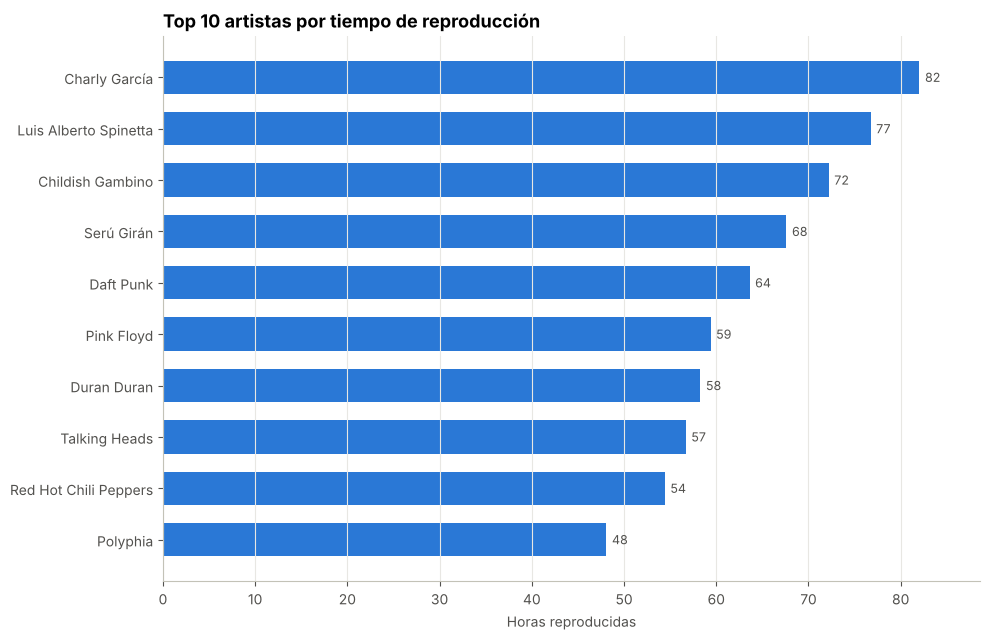

Los 10 artistas más escuchados suman el 18.6% del tiempo total (de 3,335 artistas distintos).


In [17]:
def graficar_ranking(valores: pd.Series, titulo: str, etiqueta_eje: str, color: str = COLOR_PRINCIPAL) -> None:
    """Gráfico de barras horizontales ordenado, con el valor escrito al final de cada barra."""
    figura, eje = plt.subplots(figsize=(10, 0.5 * len(valores) + 1.5))
    valores_ordenados: pd.Series = valores.iloc[::-1]  # el mayor queda arriba
    barras = eje.barh(valores_ordenados.index, valores_ordenados.values, color=color, height=0.65)
    eje.bar_label(barras, fmt="%.0f", padding=4, color=COLOR_TEXTO, fontsize=9)
    eje.set_title(titulo, loc="left")
    eje.set_xlabel(etiqueta_eje)
    eje.grid(axis="y", visible=False)
    eje.margins(x=0.08)
    plt.tight_layout()
    plt.show()


top10_artistas: pd.Series = horas_por_artista.head(10)
graficar_ranking(top10_artistas, "Top 10 artistas por tiempo de reproducción", "Horas reproducidas")

porcentaje_top10_artistas: float = top10_artistas.sum() / horas_totales * 100
print(f"Los 10 artistas más escuchados suman el {porcentaje_top10_artistas:.1f}% del tiempo total "
      f"(de {artistas_distintos:,} artistas distintos).")

### Punto 9: Top 10 de canciones más escuchadas

Mismo tipo de gráfico. La etiqueta incluye el artista para que no haya ambigüedad.

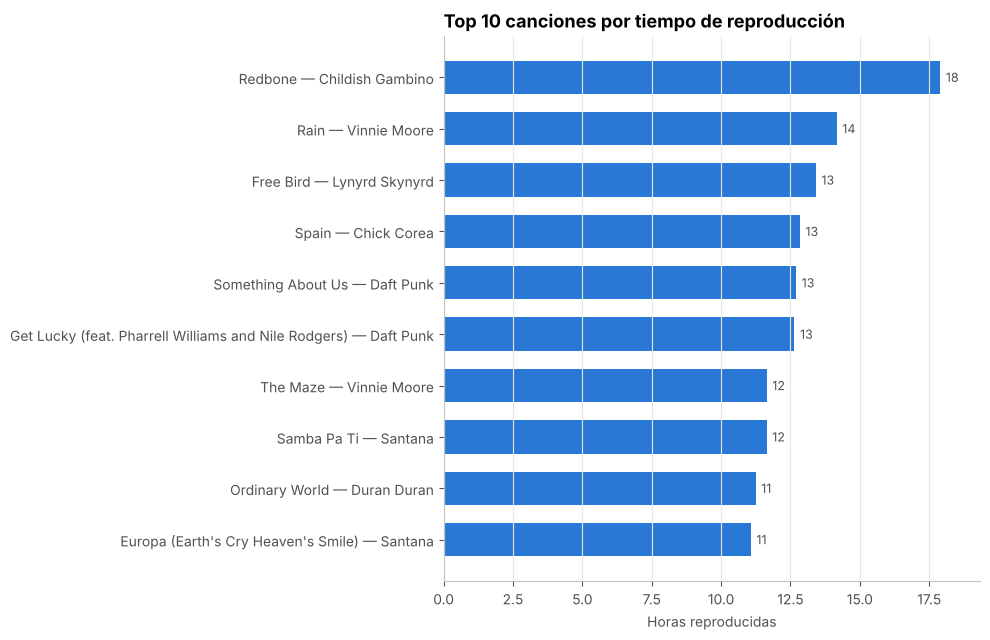

,,horas,reproducciones
cancion,artista,,
Redbone,Childish Gambino,17.9,289
Rain,Vinnie Moore,14.2,249
Free Bird,Lynyrd Skynyrd,13.4,203
Spain,Chick Corea,12.8,121
Something About Us,Daft Punk,12.7,270
Get Lucky (feat. Pharrell Williams and Nile Rodgers),Daft Punk,12.6,286
The Maze,Vinnie Moore,11.6,169
Samba Pa Ti,Santana,11.6,243
Ordinary World,Duran Duran,11.2,237


In [18]:
# Etiqueta "Canción — Artista" para el gráfico
top10_canciones: pd.Series = resumen_por_cancion["horas"].head(10)
top10_canciones.index = [f"{cancion} — {artista}" for cancion, artista in top10_canciones.index]

graficar_ranking(top10_canciones, "Top 10 canciones por tiempo de reproducción", "Horas reproducidas")
resumen_por_cancion.head(10).round(1)

Se puede ver que el ranking de canciones está dominado por el mismo grupo de artistas del top 10.

## 4. Análisis adicionales

Se plantean cuatro preguntas extra:

- **A.** ¿Cómo cambió el tiempo de escucha a lo largo de los años?
- **B.** ¿Desde qué dispositivos escucha?
- **C.** ¿Cuántas canciones escucha completas y cuántas saltea? ¿Influye el modo aleatorio?
- **D.** ¿Sigue descubriendo artistas nuevos o escucha siempre los mismos?

### A. Evolución del tiempo de escucha

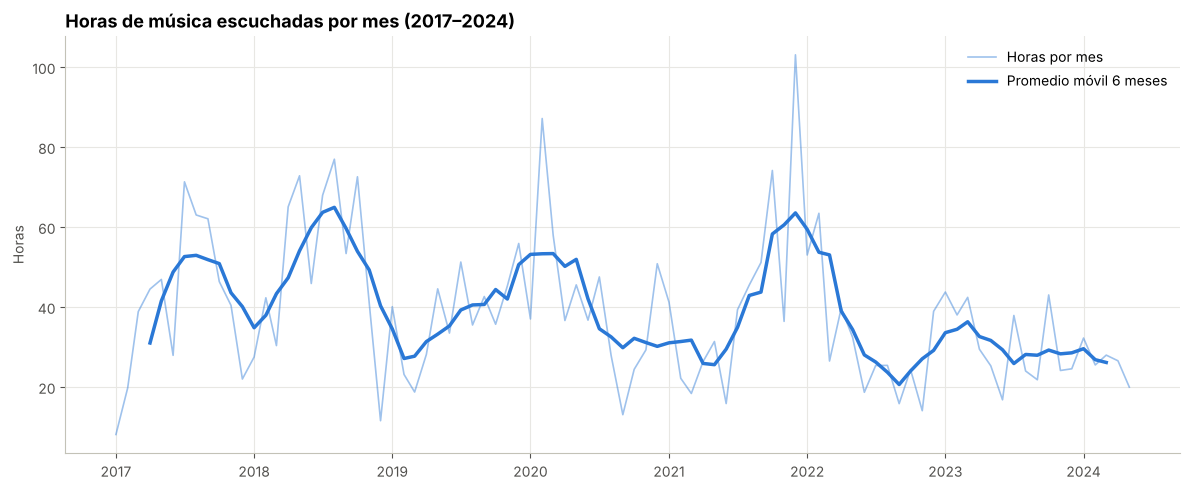

Mes con más escucha: Dic 2021 (103 horas)


In [19]:
# Horas por mes (año-mes) para ver la evolución en el tiempo
horas_por_mes: pd.Series = df_canciones.set_index("fecha")["horas"].resample("MS").sum()
horas_por_mes = horas_por_mes[horas_por_mes.index.year >= 2017]  # antes de 2017 casi no hay datos

# Promedio móvil de 6 meses para suavizar la tendencia
tendencia_6_meses: pd.Series = horas_por_mes.rolling(6, center=True).mean()

figura, eje = plt.subplots(figsize=(12, 5))
eje.plot(horas_por_mes.index, horas_por_mes.values, color=COLOR_PRINCIPAL, linewidth=1.2,
         alpha=0.45, label="Horas por mes")
eje.plot(tendencia_6_meses.index, tendencia_6_meses.values, color=COLOR_PRINCIPAL, linewidth=2.5,
         label="Promedio móvil 6 meses")
eje.set_title("Horas de música escuchadas por mes (2017–2024)", loc="left")
eje.set_ylabel("Horas")
eje.legend(frameon=False)
plt.tight_layout()
plt.show()

mes_pico: pd.Timestamp = horas_por_mes.idxmax()
print(f"Mes con más escucha: {MESES[mes_pico.month - 1]} {mes_pico.year} ({horas_por_mes.max():.0f} horas)")

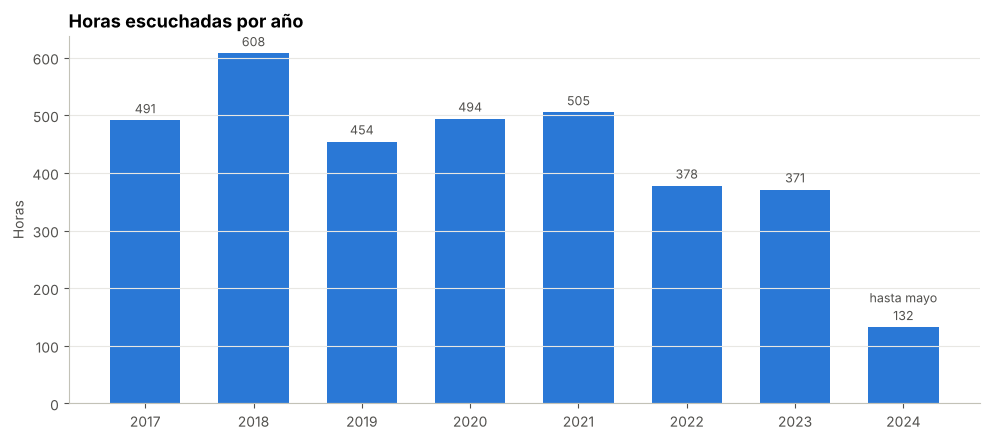

In [20]:
# Totales por año (2024 está incompleto: llega hasta mayo)
horas_por_anio: pd.Series = df_canciones[df_canciones["anio"] >= 2017].groupby("anio")["horas"].sum()

figura, eje = plt.subplots(figsize=(10, 4.5))
barras = eje.bar(horas_por_anio.index.astype(str), horas_por_anio.values, color=COLOR_PRINCIPAL, width=0.65)
eje.bar_label(barras, fmt="%.0f", padding=3, color=COLOR_TEXTO, fontsize=9)
eje.set_title("Horas escuchadas por año", loc="left")
eje.set_ylabel("Horas")
eje.grid(axis="x", visible=False)
eje.annotate("hasta mayo", xy=(len(horas_por_anio) - 1, horas_por_anio.iloc[-1]), xytext=(0, 18),
             textcoords="offset points", ha="center", fontsize=9, color=COLOR_TEXTO)
plt.tight_layout()
plt.show()

**Conclusión A:** el año con más horas fue **2018** (~608 h). Entre 2019 y 2021 el consumo se mantuvo
estable (~450–500 h por año) y desde 2022 bajó a unas 370–380 h anuales. El gráfico mensual muestra
picos puntuales muy marcados (por ejemplo, **diciembre de 2021**, con más de 100 horas) y una tendencia
general a la baja en los últimos años.

Un detalle: 2020 es el año con **más reproducciones** pero no con más horas. Eso indica que ese año
saltó más canciones (muchas reproducciones cortas).

### B. Dispositivos utilizados

La columna `plataforma` tiene muchos valores distintos (cada versión de sistema operativo es un valor
distinto). Se agrupan en categorías generales.

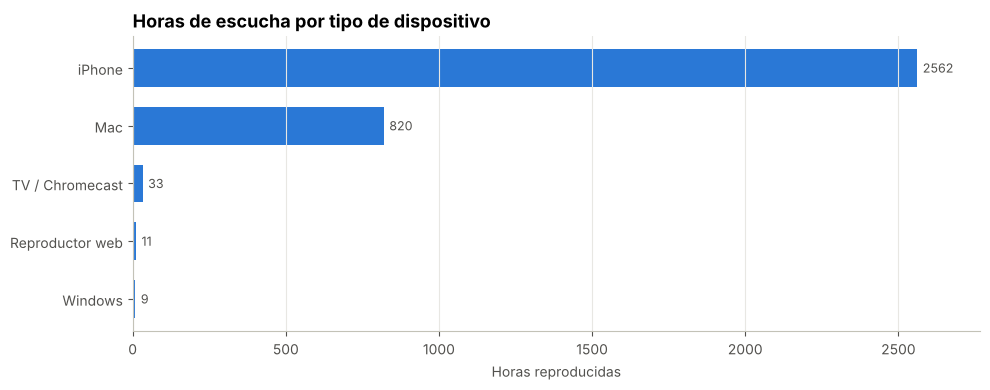

Porcentaje del tiempo por dispositivo:
dispositivo
iPhone             74.6
Mac                23.9
TV / Chromecast     1.0
Reproductor web     0.3
Windows             0.3


In [21]:
def categorizar_plataforma(plataforma: str) -> str:
    """Agrupa el texto de la plataforma en una categoría de dispositivo."""
    texto: str = plataforma.lower()
    if "apple_tv" in texto or "cast_tv" in texto:
        return "TV / Chromecast"
    if "web_player" in texto or "webplayer" in texto:
        return "Reproductor web"
    if texto.startswith("ios") or "iphone" in texto or "applewatch" in texto:
        return "iPhone"
    if texto.startswith("os x") or texto.startswith("osx"):
        return "Mac"
    if texto.startswith("windows"):
        return "Windows"
    return "Otros"


df_canciones["dispositivo"] = df_canciones["plataforma"].map(categorizar_plataforma)

horas_por_dispositivo: pd.Series = (
    df_canciones.groupby("dispositivo")["horas"].sum().sort_values(ascending=False)
)
graficar_ranking(horas_por_dispositivo, "Horas de escucha por tipo de dispositivo", "Horas reproducidas")

porcentajes_dispositivo: pd.Series = (horas_por_dispositivo / horas_por_dispositivo.sum() * 100).round(1)
print("Porcentaje del tiempo por dispositivo:")
print(porcentajes_dispositivo.to_string())

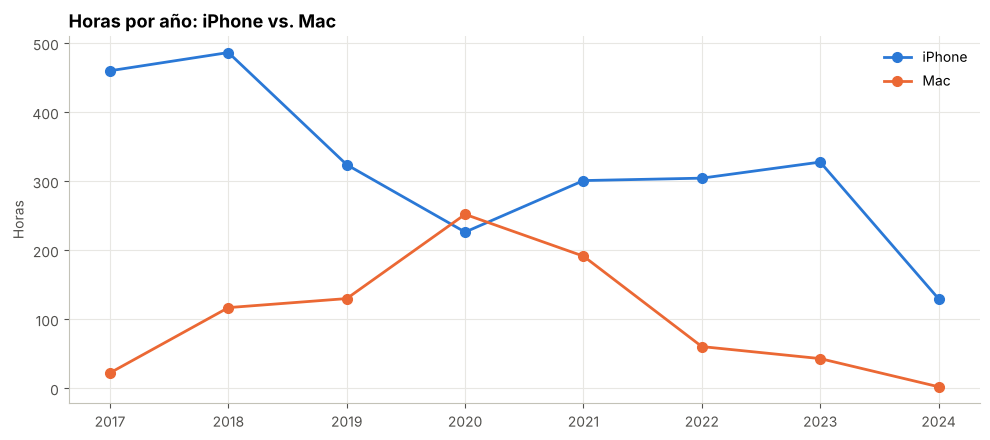

In [22]:
# ¿Cambió el uso de cada dispositivo con los años? (solo los dos principales)
horas_dispositivo_anio: pd.DataFrame = (
    df_canciones[(df_canciones["anio"] >= 2017) & df_canciones["dispositivo"].isin(["iPhone", "Mac"])]
    .pivot_table(index="anio", columns="dispositivo", values="horas", aggfunc="sum")
)

figura, eje = plt.subplots(figsize=(10, 4.5))
eje.plot(horas_dispositivo_anio.index, horas_dispositivo_anio["iPhone"], marker="o", markersize=7,
         linewidth=2, color=COLOR_PRINCIPAL, label="iPhone")
eje.plot(horas_dispositivo_anio.index, horas_dispositivo_anio["Mac"], marker="o", markersize=7,
         linewidth=2, color=COLOR_SECUNDARIO, label="Mac")
eje.set_title("Horas por año: iPhone vs. Mac", loc="left")
eje.set_ylabel("Horas")
eje.legend(frameon=False)
plt.tight_layout()
plt.show()

**Conclusión B:** tres cuartos del tiempo (~75%) se escucha desde el **iPhone** y casi todo el resto
desde una **Mac** (~24%). Web, Windows y TV son marginales. Lo más interesante es la evolución:
el uso de la Mac crece hasta que en **2020 supera al iPhone**, lo que coincide con la pandemia (más
tiempo en casa frente a la computadora). Desde 2022 la Mac casi desaparece y el celular vuelve a ser
el dispositivo principal.

### C. ¿Escucha las canciones completas o las saltea?

Se considera una reproducción **corta** a la que dura menos de 30 segundos (es el umbral que usa Spotify
para contar una reproducción). También se mira el motivo de fin (`motivo_fin`) y se compara con y sin
modo aleatorio (`shuffle`).

El 52.7% de las reproducciones duró menos de 30 segundos.



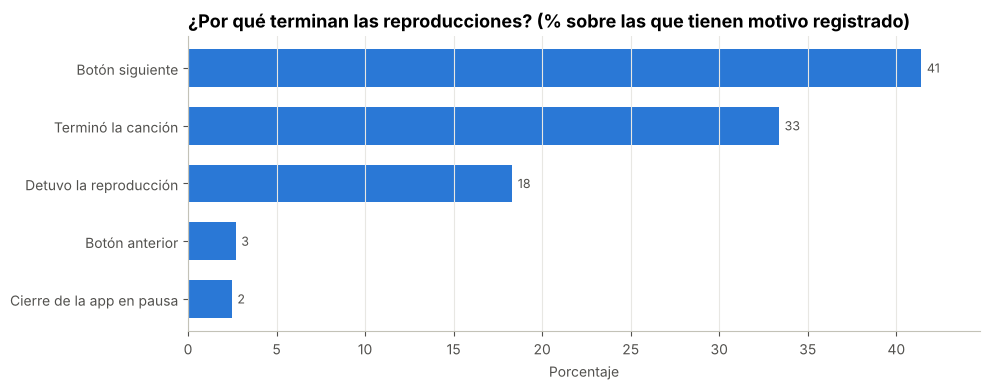

In [23]:
UMBRAL_REPRODUCCION_CORTA_MS: int = 30_000
df_canciones["es_corta"] = df_canciones["ms_played"] < UMBRAL_REPRODUCCION_CORTA_MS

porcentaje_cortas: float = df_canciones["es_corta"].mean() * 100
print(f"El {porcentaje_cortas:.1f}% de las reproducciones duró menos de 30 segundos.\n")

# Motivos por los que terminó la reproducción (los 5 más frecuentes)
DESCRIPCION_MOTIVOS: dict[str, str] = {
    "fwdbtn": "Botón siguiente",
    "trackdone": "Terminó la canción",
    "endplay": "Detuvo la reproducción",
    "backbtn": "Botón anterior",
    "unexpected-exit-while-paused": "Cierre de la app en pausa",
}
motivos_fin: pd.Series = (
    df_canciones["motivo_fin"].value_counts(normalize=True).head(5).mul(100)
    .rename(index=DESCRIPCION_MOTIVOS)
)
graficar_ranking(motivos_fin, "¿Por qué terminan las reproducciones? (% sobre las que tienen motivo registrado)", "Porcentaje")

               reproducciones  porcentaje_cortas  porcentaje_completas
shuffle                                                               
Sin aleatorio           29912               39.3                  37.1
Con aleatorio           94041               56.9                  25.3 



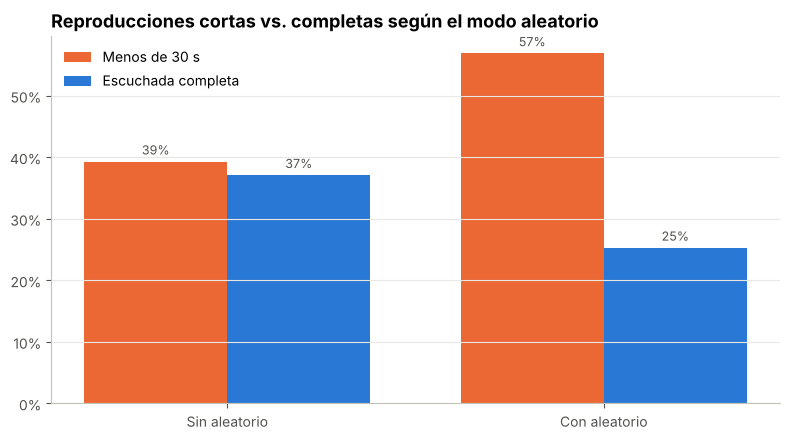

In [24]:
# Comparación con y sin modo aleatorio
comparacion_shuffle: pd.DataFrame = (
    df_canciones.groupby("shuffle")
    .agg(
        reproducciones=("ms_played", "size"),
        porcentaje_cortas=("es_corta", lambda serie: serie.mean() * 100),
        porcentaje_completas=("motivo_fin", lambda serie: (serie == "trackdone").mean() * 100),
    )
    .rename(index={True: "Con aleatorio", False: "Sin aleatorio"})
    .round(1)
)
print(comparacion_shuffle, "\n")

figura, eje = plt.subplots(figsize=(8, 4.5))
posiciones = range(len(comparacion_shuffle))
ancho: float = 0.38
barras_cortas = eje.bar([p - ancho / 2 for p in posiciones], comparacion_shuffle["porcentaje_cortas"],
                        width=ancho, color=COLOR_SECUNDARIO, label="Menos de 30 s")
barras_completas = eje.bar([p + ancho / 2 for p in posiciones], comparacion_shuffle["porcentaje_completas"],
                           width=ancho, color=COLOR_PRINCIPAL, label="Escuchada completa")
eje.bar_label(barras_cortas, fmt="%.0f%%", padding=3, color=COLOR_TEXTO, fontsize=9)
eje.bar_label(barras_completas, fmt="%.0f%%", padding=3, color=COLOR_TEXTO, fontsize=9)
eje.set_xticks(list(posiciones), comparacion_shuffle.index)
eje.yaxis.set_major_formatter(mticker.PercentFormatter())
eje.set_title("Reproducciones cortas vs. completas según el modo aleatorio", loc="left")
eje.legend(frameon=False)
eje.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Conclusión C:** el usuario saltea mucho. **Más de la mitad (53%)** de las reproducciones dura menos
de 30 segundos, y el motivo de fin más común es el **botón siguiente** (41%), por encima de que la
canción termine sola (33%). Además, 3 de cada 4 reproducciones son en modo aleatorio, y ahí el efecto
es más fuerte: con aleatorio el 57% son cortas y solo el 25% se escucha completa, contra 39% y 37% sin
aleatorio. Cuando la canción la elige Spotify, es mucho más probable pasarla.

### D. ¿Descubre artistas nuevos?

Para cada artista se toma el año de su **primera** reproducción y se cuenta cuántos artistas nuevos
aparecen cada año. Para no contar artistas escuchados por casualidad, solo se consideran los que
acumularon al menos 30 minutos en total.

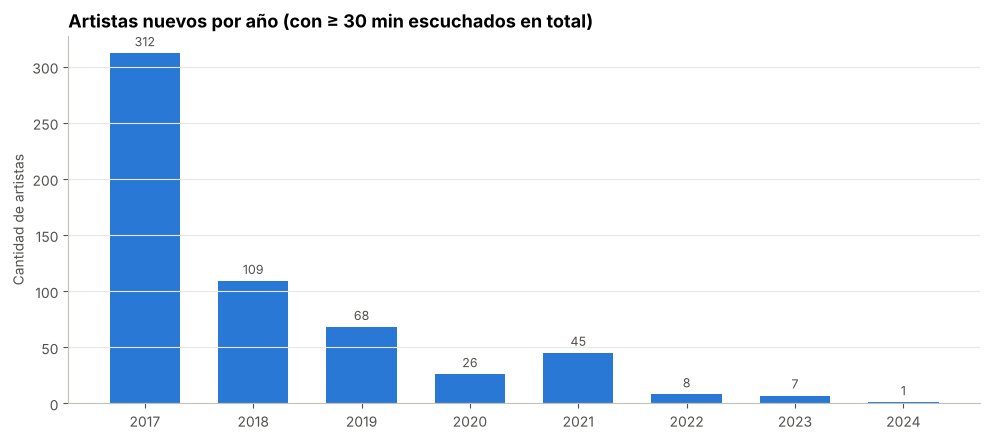

Año de primera escucha de los artistas del top 10:
artista
Charly García            2017
Luis Alberto Spinetta    2017
Childish Gambino         2018
Serú Girán               2018
Daft Punk                2017
Pink Floyd               2017
Duran Duran              2017
Talking Heads            2017
Red Hot Chili Peppers    2017
Polyphia                 2020


In [25]:
MINUTOS_MINIMOS_ARTISTA: int = 30

resumen_artistas: pd.DataFrame = df_canciones.groupby("artista").agg(
    primer_anio=("anio", "min"),
    horas=("horas", "sum"),
)
artistas_relevantes: pd.DataFrame = resumen_artistas[resumen_artistas["horas"] * 60 >= MINUTOS_MINIMOS_ARTISTA]

artistas_nuevos_por_anio: pd.Series = (
    artistas_relevantes[artistas_relevantes["primer_anio"] >= 2017].groupby("primer_anio").size()
)

figura, eje = plt.subplots(figsize=(10, 4.5))
barras = eje.bar(artistas_nuevos_por_anio.index.astype(str), artistas_nuevos_por_anio.values,
                 color=COLOR_PRINCIPAL, width=0.65)
eje.bar_label(barras, padding=3, color=COLOR_TEXTO, fontsize=9)
eje.set_title(f"Artistas nuevos por año (con ≥ {MINUTOS_MINIMOS_ARTISTA} min escuchados en total)", loc="left")
eje.set_ylabel("Cantidad de artistas")
eje.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# ¿En qué año descubrió a los artistas del top 10?
print("Año de primera escucha de los artistas del top 10:")
print(resumen_artistas.loc[top10_artistas.index, "primer_anio"].to_string())

**Conclusión D:** 2017 tiene muchos artistas "nuevos" (312) porque es el primer año con datos y
incluye artistas que el usuario ya conocía. Después la cantidad cae año a año (109 en 2018, 68 en
2019, 26 en 2020) y desde 2022 apenas aparecen unos pocos. El usuario **explora cada vez menos** y se
queda con lo conocido. Lo confirma el top 10: 9 de sus 10 artistas favoritos ya estaban en 2017–2018;
la única excepción es **Polyphia** (descubierto en 2020), que en los últimos años pasó a ser su artista
más escuchado mes a mes.

## 5. Bonus

### ¿Qué día de la semana y en qué horario se escucha más música?

Se usa la hora **local** (Argentina). Como el historial cubre varios años, el total por día ya es
comparable (cada día de la semana aparece la misma cantidad de veces).

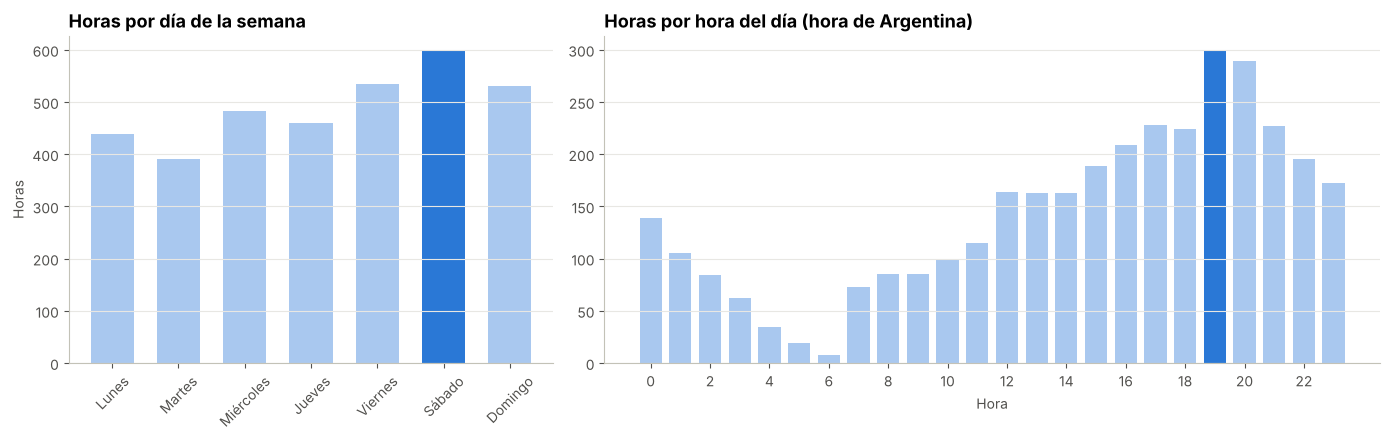

Día con más escucha: Sábado (597 horas)
Día con menos escucha: Martes (390 horas)
Hora con más escucha: 19:00 a 20:00 hs


In [26]:
horas_por_dia: pd.Series = df_canciones.groupby("dia_semana")["horas"].sum()
horas_por_dia.index = DIAS_SEMANA

horas_por_hora: pd.Series = df_canciones.groupby("hora")["horas"].sum().reindex(range(24), fill_value=0)

figura, (eje_dias, eje_horas) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

# Días de la semana: se resalta el máximo
colores_dias: list[str] = [COLOR_PRINCIPAL if dia == horas_por_dia.idxmax() else "#a9c8ef" for dia in horas_por_dia.index]
eje_dias.bar(horas_por_dia.index, horas_por_dia.values, color=colores_dias, width=0.65)
eje_dias.set_title("Horas por día de la semana", loc="left")
eje_dias.set_ylabel("Horas")
eje_dias.tick_params(axis="x", rotation=45)
eje_dias.grid(axis="x", visible=False)

# Horas del día: se resalta el máximo
colores_horas: list[str] = [COLOR_PRINCIPAL if hora == horas_por_hora.idxmax() else "#a9c8ef" for hora in horas_por_hora.index]
eje_horas.bar(horas_por_hora.index, horas_por_hora.values, color=colores_horas, width=0.75)
eje_horas.set_title("Horas por hora del día (hora de Argentina)", loc="left")
eje_horas.set_xlabel("Hora")
eje_horas.set_xticks(range(0, 24, 2))
eje_horas.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"Día con más escucha: {horas_por_dia.idxmax()} ({horas_por_dia.max():,.0f} horas)")
print(f"Día con menos escucha: {horas_por_dia.idxmin()} ({horas_por_dia.min():,.0f} horas)")
print(f"Hora con más escucha: {horas_por_hora.idxmax()}:00 a {horas_por_hora.idxmax() + 1}:00 hs")

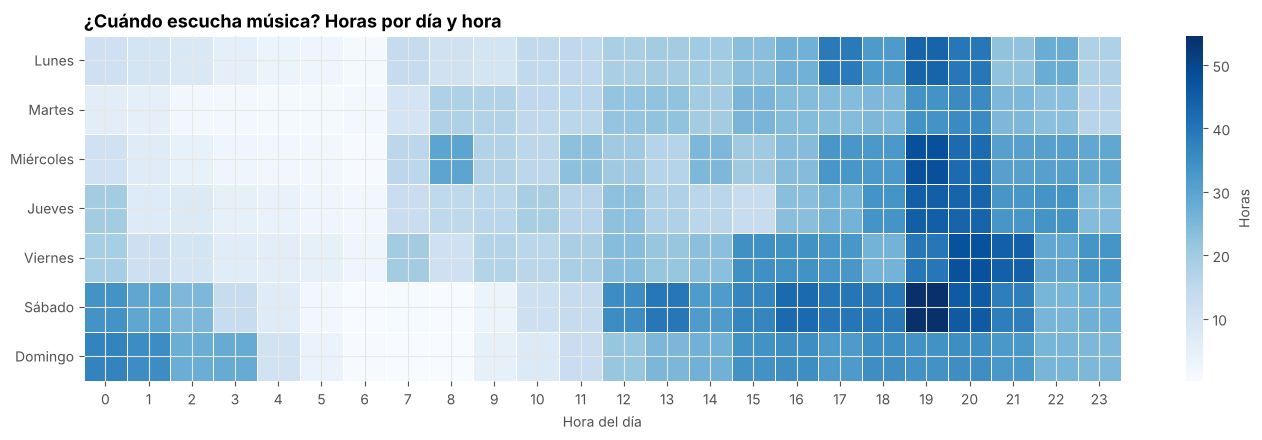

In [27]:
# Mapa de calor: combina día de la semana y hora del día
matriz_dia_hora: pd.DataFrame = df_canciones.pivot_table(
    index="dia_semana", columns="hora", values="horas", aggfunc="sum", fill_value=0
).reindex(columns=range(24), fill_value=0)
matriz_dia_hora.index = DIAS_SEMANA

figura, eje = plt.subplots(figsize=(14, 4.5))
sns.heatmap(matriz_dia_hora, cmap="Blues", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Horas"}, ax=eje)
eje.set_title("¿Cuándo escucha música? Horas por día y hora", loc="left")
eje.set_xlabel("Hora del día")
eje.set_ylabel("")
plt.tight_layout()
plt.show()

**Respuesta:** el día con más escucha es el **sábado** y el de menos, el **martes**. La hora pico es
entre las **19 y las 20 hs**. El mapa de calor muestra dos patrones:

- **Días de semana:** casi nada a la mañana temprano y un pico claro a la tarde-noche (17 a 21 hs),
  probablemente al volver de las actividades del día.
- **Fines de semana:** la escucha arranca después del mediodía y se extiende hasta la madrugada del
  sábado y del domingo (0 a 3 hs), es decir, los viernes y sábados a la noche.

### ¿En qué mes se escucha más música?

Para comparar meses de forma justa se usan solo los **años completos (2017 a 2023)**. Si se incluyera
2024 (que llega hasta mayo), los meses de enero a mayo tendrían un año extra de datos y quedarían
inflados.

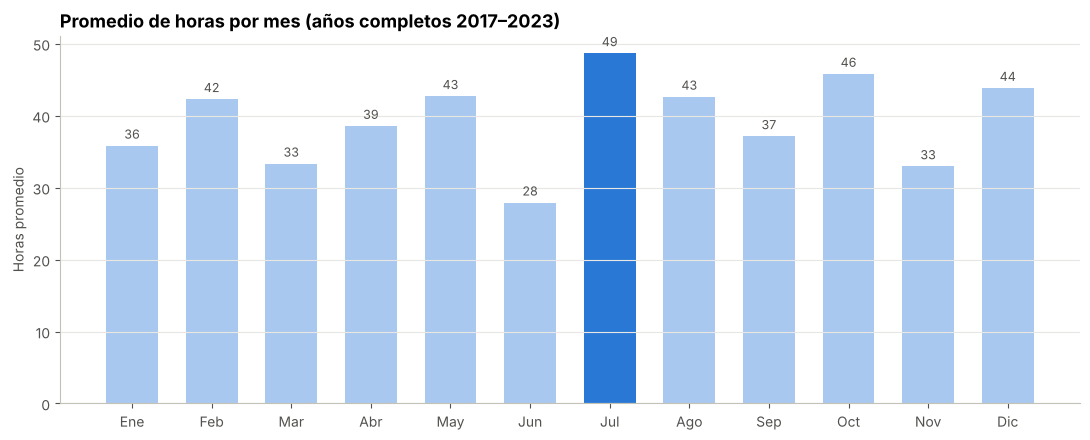

Mes con más escucha (promedio): Jul (49 horas)
Mes con menos escucha (promedio): Jun (28 horas)


In [28]:
ANIOS_COMPLETOS: range = range(2017, 2024)
df_anios_completos: pd.DataFrame = df_canciones[df_canciones["anio"].isin(ANIOS_COMPLETOS)]

# Promedio de horas de cada mes calendario a lo largo de los años completos
horas_promedio_por_mes: pd.Series = (
    df_anios_completos.groupby(["anio", "mes"])["horas"].sum()
    .groupby("mes").mean()
)
horas_promedio_por_mes.index = MESES

figura, eje = plt.subplots(figsize=(11, 4.5))
colores_meses: list[str] = [COLOR_PRINCIPAL if mes == horas_promedio_por_mes.idxmax() else "#a9c8ef"
                            for mes in horas_promedio_por_mes.index]
barras = eje.bar(horas_promedio_por_mes.index, horas_promedio_por_mes.values, color=colores_meses, width=0.65)
eje.bar_label(barras, fmt="%.0f", padding=3, color=COLOR_TEXTO, fontsize=9)
eje.set_title("Promedio de horas por mes (años completos 2017–2023)", loc="left")
eje.set_ylabel("Horas promedio")
eje.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Mes con más escucha (promedio): {horas_promedio_por_mes.idxmax()} "
      f"({horas_promedio_por_mes.max():.0f} horas)")
print(f"Mes con menos escucha (promedio): {horas_promedio_por_mes.idxmin()} "
      f"({horas_promedio_por_mes.min():.0f} horas)")

**Respuesta:** en promedio, **julio** es el mes con más escucha (~49 h) y **junio** el de menos (~28 h).
Julio coincide con las vacaciones de invierno. Igual hay que tomarlo con cuidado: con solo 7 años
completos, un mes muy alto (como el pico de diciembre de 2021) pesa bastante en el promedio.

### ¿Cuál es el artista más escuchado en cada mes?

Se responde de dos formas:

1. Por **mes calendario** (enero, febrero, …) sumando todos los años completos.
2. Por **cada mes del historial** (año-mes), contando cuántos meses fue el número 1 cada artista.

In [29]:
# 1) Artista más escuchado en cada mes calendario (2017-2023)
horas_artista_mes: pd.Series = df_anios_completos.groupby(["mes", "artista"])["horas"].sum()
indice_maximos = horas_artista_mes.groupby("mes").idxmax()

artista_top_por_mes: pd.DataFrame = (
    horas_artista_mes.loc[indice_maximos].reset_index()
    .assign(mes=lambda tabla: tabla["mes"].map(lambda numero: MESES[numero - 1]))
    .rename(columns={"mes": "Mes", "artista": "Artista más escuchado", "horas": "Horas"})
    .round(1)
)
artista_top_por_mes

,Mes,Artista más escuchado,Horas
0,Ene,Red Hot Chili Peppers,5.5
1,Feb,Talking Heads,12.6
2,Mar,Childish Gambino,6.4
3,Abr,Talking Heads,7.6
4,May,Childish Gambino,14.7
5,Jun,Luis Alberto Spinetta,6.8
6,Jul,Polyphia,15.8
7,Ago,Luis Alberto Spinetta,16.7
8,Sep,Charly García,10.4
9,Oct,Charly García,21.0


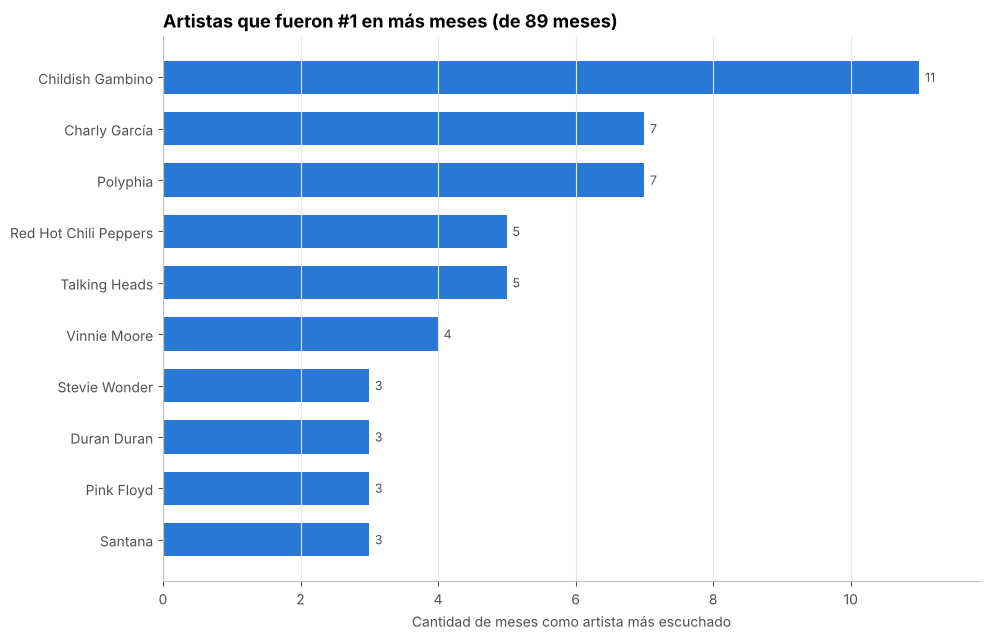

Últimos 12 meses del historial:
anio_mes
2023-06         Polyphia
2023-07         Polyphia
2023-08         Polyphia
2023-09         Dua Lipa
2023-10    Scary Pockets
2023-11         Polyphia
2023-12         Polyphia
2024-01              FKJ
2024-02              FKJ
2024-03              FKJ
2024-04           Trueno
2024-05         Polyphia


In [30]:
# 2) Para cada mes del historial (año-mes), quién fue el artista más escuchado
horas_artista_anio_mes: pd.Series = (
    df_canciones[df_canciones["anio"] >= 2017].groupby(["anio_mes", "artista"])["horas"].sum()
)
artista_top_cada_mes: pd.Series = (
    horas_artista_anio_mes.loc[horas_artista_anio_mes.groupby("anio_mes").idxmax()]
    .reset_index().set_index("anio_mes")["artista"]
)

meses_como_numero_uno: pd.Series = artista_top_cada_mes.value_counts().head(10)
graficar_ranking(meses_como_numero_uno,
                 f"Artistas que fueron #1 en más meses (de {len(artista_top_cada_mes)} meses)",
                 "Cantidad de meses como artista más escuchado")

print("Últimos 12 meses del historial:")
print(artista_top_cada_mes.tail(12).to_string())

### ¿Cuál es la canción más veces salteada?

La columna `salteada` (`skipped`) **solo se registró desde fines de 2022**, así que usarla sola deja
afuera la mayor parte del historial:

In [31]:
# Porcentaje de registros con dato en 'salteada' por año
cobertura_salteada: pd.Series = (df_canciones.groupby("anio")["salteada"].apply(lambda serie: serie.notna().mean() * 100)).round(1)
print("Porcentaje de reproducciones con dato de 'salteada', por año:")
print(cobertura_salteada.to_string())

Porcentaje de reproducciones con dato de 'salteada', por año:
anio
2014    100.0
2016      0.0
2017      0.0
2018      0.0
2019      0.0
2020      0.0
2021      0.1
2022     16.6
2023    100.0
2024    100.0


Por eso se define "salteada" de una forma que sirve para todo el período: **la reproducción terminó por
el botón siguiente (`fwdbtn`) antes de los 30 segundos**. Después se compara con el resultado de la
columna `salteada` en el período en que existe.

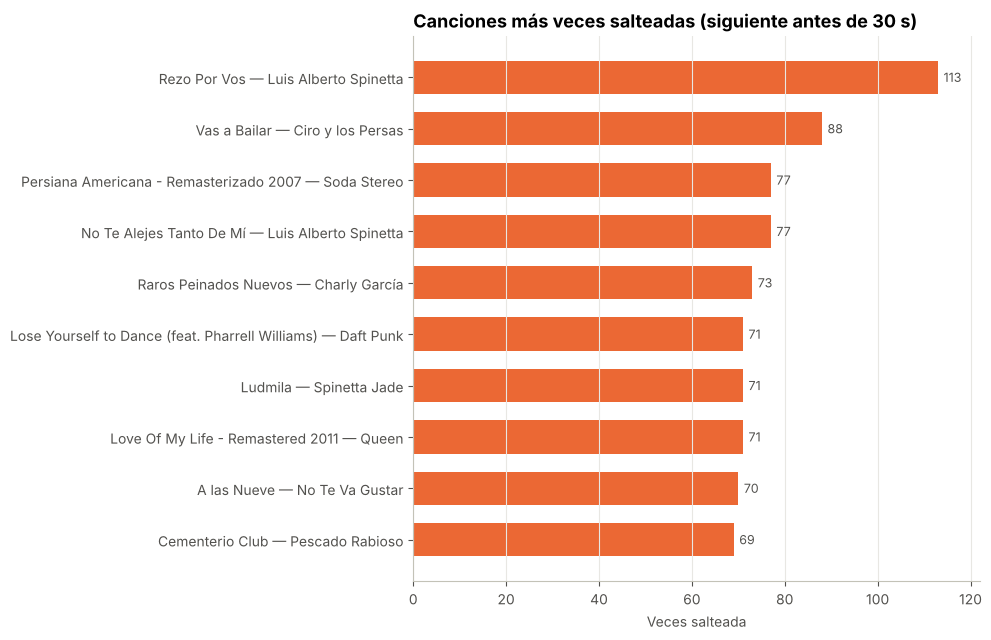

,veces_salteada,reproducciones,porcentaje_salteo
cancion_artista,,,
Rezo Por Vos — Luis Alberto Spinetta,113,360,31.4
Vas a Bailar — Ciro y los Persas,88,190,46.3
Persiana Americana - Remasterizado 2007 — Soda Stereo,77,201,38.3
No Te Alejes Tanto De Mí — Luis Alberto Spinetta,77,299,25.8
Raros Peinados Nuevos — Charly García,73,226,32.3
Lose Yourself to Dance (feat. Pharrell Williams) — Daft Punk,71,224,31.7
Ludmila — Spinetta Jade,71,143,49.7
Love Of My Life - Remastered 2011 — Queen,71,144,49.3
A las Nueve — No Te Va Gustar,70,193,36.3


In [32]:
# Definición propia: terminó con "siguiente" antes de los 30 segundos
df_canciones["salteo_rapido"] = (df_canciones["motivo_fin"] == "fwdbtn") & df_canciones["es_corta"]

salteos_por_cancion: pd.DataFrame = (
    df_canciones.groupby("cancion_artista")
    .agg(veces_salteada=("salteo_rapido", "sum"), reproducciones=("salteo_rapido", "size"))
    .assign(porcentaje_salteo=lambda tabla: (tabla["veces_salteada"] / tabla["reproducciones"] * 100).round(1))
    .sort_values("veces_salteada", ascending=False)
)

top10_salteadas: pd.Series = salteos_por_cancion["veces_salteada"].head(10)
graficar_ranking(top10_salteadas, "Canciones más veces salteadas (siguiente antes de 30 s)",
                 "Veces salteada", color=COLOR_SECUNDARIO)
salteos_por_cancion.head(10)

In [33]:
# Comparación con la columna original 'salteada' (solo desde fines de 2022)
salteadas_segun_columna: pd.Series = (
    df_canciones[df_canciones["salteada"] == True]  # noqa: E712 (columna booleana con nulos)
    .groupby("cancion_artista").size().sort_values(ascending=False)
)
print("Más salteadas según la columna 'skipped' (fines 2022 – 2024):")
print(salteadas_segun_columna.head(5).to_string())

Más salteadas según la columna 'skipped' (fines 2022 – 2024):
cancion_artista
Bloodbath (feat. Chino Moreno) — Polyphia    39
Igot — Kidd Keo                              38
Playing God — Polyphia                       33
Ego Death (feat. Steve Vai) — Polyphia       31
The Less I Know The Better — Tame Impala     27


**Respuesta:** la canción más veces salteada es **"Rezo Por Vos" de Luis Alberto Spinetta** (113
veces). Pero hay un detalle interesante: también es la canción con **más reproducciones** de todo el
historial (360). Se saltea mucho porque aparece muchísimo. Por eso también se muestra el
`porcentaje_salteo`: en proporción, otras canciones (como "Ludmila" o "Love Of My Life", con casi 50%)
se saltean bastante más.

Con la columna original `skipped` (solo fines de 2022 en adelante) las más salteadas son de
**Polyphia**, que es justamente el artista que más escuchó en ese período.

## 6. Bonus 2: información adicional con la API de Spotify

Con `spotipy` se puede consultar la API de Spotify para traer datos extra de las canciones del top 10,
como la portada del álbum, la popularidad o los géneros del artista.

**Aclaraciones importantes:**

- Hace falta crear una app en el [Spotify Developer Dashboard](https://developer.spotify.com/dashboard)
  para obtener un `CLIENT_ID` y un `CLIENT_SECRET`. Desde 2026, el modo de desarrollo requiere que la
  cuenta del desarrollador sea **Premium**.
- El endpoint `audio_features` (energía, tempo, danceability) **ya no está disponible para apps nuevas**:
  Spotify lo restringió en noviembre de 2024. Por eso no se usa acá.
- Las credenciales **no se escriben en el código**: se leen de variables de entorno. Si no están
  configuradas, la celda lo avisa y no se ejecuta (así el notebook corre sin errores igual).

Para usarlo: `pip install spotipy` y definir las variables `SPOTIPY_CLIENT_ID` y `SPOTIPY_CLIENT_SECRET`
antes de abrir Jupyter.

In [34]:
import os

client_id: str | None = os.environ.get("SPOTIPY_CLIENT_ID")
client_secret: str | None = os.environ.get("SPOTIPY_CLIENT_SECRET")

if not (client_id and client_secret):
    print("No hay credenciales de Spotify configuradas: se omite la consulta a la API.")
    print("Definir SPOTIPY_CLIENT_ID y SPOTIPY_CLIENT_SECRET para ejecutar esta parte.")
else:
    import spotipy
    from spotipy.oauth2 import SpotifyClientCredentials

    cliente_spotify = spotipy.Spotify(
        auth_manager=SpotifyClientCredentials(client_id=client_id, client_secret=client_secret)
    )

    # URI más reproducido de cada canción del top 10
    uris_top10: list[str] = [
        df_canciones.loc[(df_canciones["cancion"] == cancion) & (df_canciones["artista"] == artista), "uri"]
        .mode().iloc[0]
        for cancion, artista in resumen_por_cancion.head(10).index
    ]

    filas_api: list[dict] = []
    for uri in uris_top10:
        pista: dict = cliente_spotify.track(uri)  # una consulta por canción (pocas: respeta el límite)
        filas_api.append({
            "cancion": pista["name"],
            "artista": pista["artists"][0]["name"],
            "album": pista["album"]["name"],
            "lanzamiento": pista["album"].get("release_date"),
            "duracion_min": round(pista["duration_ms"] / 60_000, 2),
            "portada": pista["album"]["images"][0]["url"] if pista["album"]["images"] else None,
        })

    df_info_api: pd.DataFrame = pd.DataFrame(filas_api)
    display(df_info_api)

No hay credenciales de Spotify configuradas: se omite la consulta a la API.
Definir SPOTIPY_CLIENT_ID y SPOTIPY_CLIENT_SECRET para ejecutar esta parte.


## 7. Conclusiones

**Sobre los datos**

- El dataset tiene 125.349 registros de un solo usuario, entre junio de 2014 y mayo de 2024, aunque el
  uso real empieza en 2017. No todos los registros son canciones: hay podcasts y registros sin
  metadata, que se descartaron. Varias columnas no aportaban información (`username`,
  `user_agent_decrypted`, `offline_timestamp`) y la columna `skipped` necesitó limpieza.
- Para identificar canciones se usó **nombre + artista**, porque el nombre solo mezcla canciones
  distintas (hay 7 canciones llamadas "Friends") y el URI separa una misma canción que aparece en
  varios álbumes.

**Sobre los hábitos del usuario**

- Escuchó **9.568 canciones distintas** de **3.335 artistas**, durante **3.434 horas** (unos 143 días
  completos, ~77 minutos por día desde 2017).
- Su artista más escuchado es **Charly García** (82 h), y su canción favorita de él es
  "Hablando a Tu Corazón". La canción más escuchada en general es **"Redbone" de Childish Gambino**
  (casi 18 h).
- Tiene un gusto **variado**: el top 10 de artistas suma menos del 20% del tiempo total. Mezcla rock
  nacional (Charly García, Spinetta, Serú Girán) con rock/pop internacional (Pink Floyd, Talking Heads,
  Daft Punk) y rock instrumental (Polyphia, Vinnie Moore).
- Escucha sobre todo desde el **iPhone**, a la **tarde-noche** y los **sábados**. En 2020 la
  computadora pasó al frente, en línea con la pandemia.
- **Saltea mucho**: más de la mitad de las reproducciones dura menos de 30 segundos, sobre todo en
  modo aleatorio.
- Con los años **escucha un poco menos y descubre menos artistas nuevos**. La excepción es Polyphia,
  que descubrió en 2020 y domina sus últimos meses.